In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [34]:
file_path= r"..\data\raw\healthcare-dataset-stroke-data.csv"

data=pd.read_csv(file_path)
data.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [32]:
# Explore the dataset

# Get general info: column types, non-null counts
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [19]:
# Get summary statistics for numeric columns
data.describe().T


,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.829354,21161.721625,67.00,17741.250,36932.000,54682.00,72940.00
age,5110.0,43.226614,22.612647,0.08,25.000,45.000,61.00,82.00
hypertension,5110.0,0.097456,0.296607,0.00,0.000,0.000,0.00,1.00
heart_disease,5110.0,0.054012,0.226063,0.00,0.000,0.000,0.00,1.00
avg_glucose_level,5110.0,106.147677,45.283560,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,28.893237,7.854067,10.30,23.500,28.100,33.10,97.60
stroke,5110.0,0.048728,0.215320,0.00,0.000,0.000,0.00,1.00


In [23]:
# Count of target variable 'stroke'
print("stroke value counts:")
print(data.stroke.value_counts())

stroke value counts:
stroke
0    4861
1     249
Name: count, dtype: int64


In [25]:
# -------------------------------
# 3. Check for missing values
# -------------------------------
print("\nMissing values per column:")
print(data.isnull().sum())



Missing values per column:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


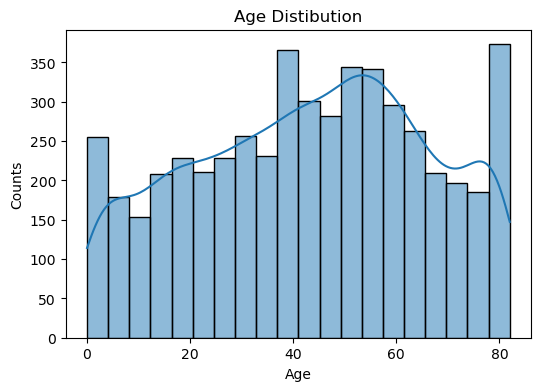

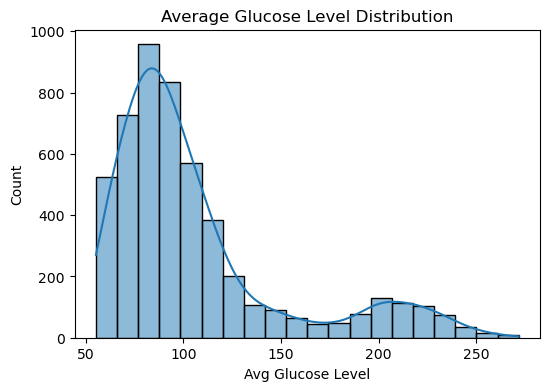

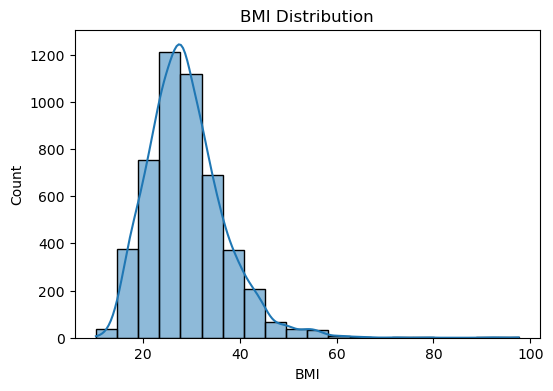

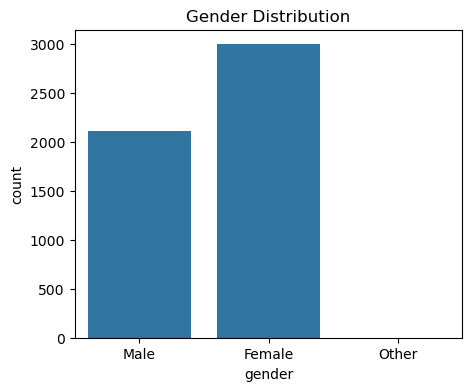

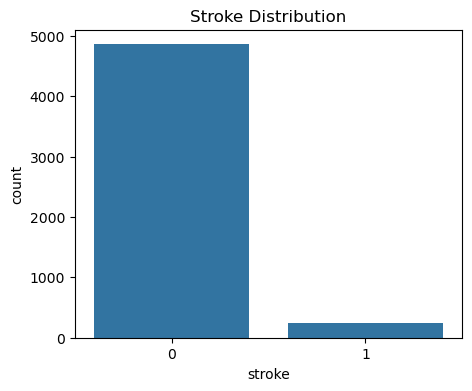

In [ ]:
# -------------------------------
# 4. Visualize some distributions
# -------------------------------

# Histogram of Age
plt.figure(figsize=(6,4))
sns.histplot(data["age"],bins=20,kde=True)
plt.title("Age Distibution")
plt.xlabel("Age")
plt.ylabel("Counts")
plt.show()


# Histogram of Avg Glucose Level
plt.figure(figsize=(6,4))
sns.histplot(data['avg_glucose_level'], bins=20, kde=True)
plt.title("Average Glucose Level Distribution")
plt.xlabel("Avg Glucose Level")
plt.ylabel("Count")
plt.show()

# Histogram of BMI
plt.figure(figsize=(6,4))
sns.histplot(data['bmi'].dropna(), bins=20, kde=True)  # dropna to ignore missing values
plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Count")
plt.show()

# Countplot for categorical variable 'gender'
plt.figure(figsize=(5,4))
sns.countplot(x='gender', data=data)
plt.title("Gender Distribution")
plt.show()

# Countplot for target variable 'stroke'
plt.figure(figsize=(5,4))
sns.countplot(x='stroke', data=data)
plt.title("Stroke Distribution")
plt.show()

<Axes: >

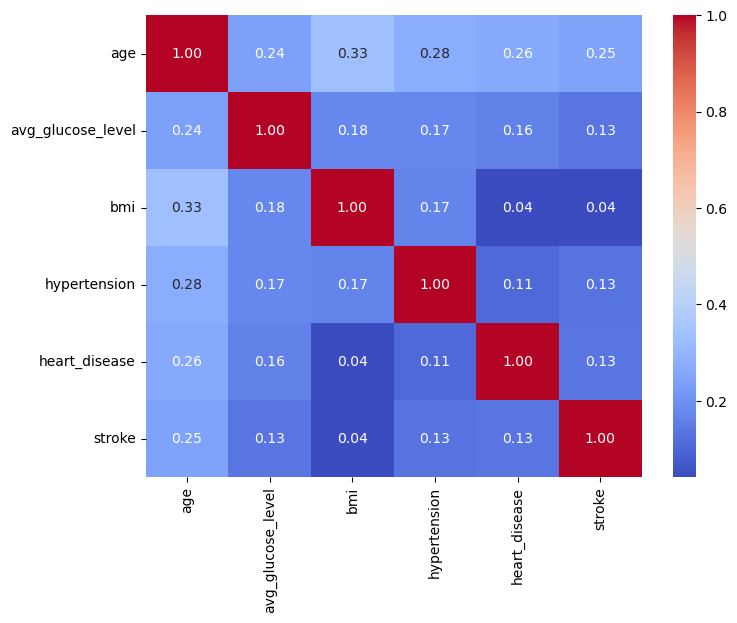

In [44]:
# 5. Check correlations
# -------------------------------
# Compute correlation matrix for numeric features

numeric_features = ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease', 'stroke']
corr_matrix= data[numeric_features].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix,annot=True, cmap='coolwarm', fmt=".2f")

Stroke value counts:
stroke
0    4861
1     249
Name: count, dtype: int64
Percentage of stroke cases: 4.87%


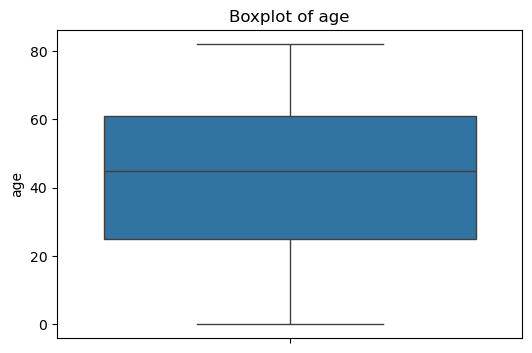

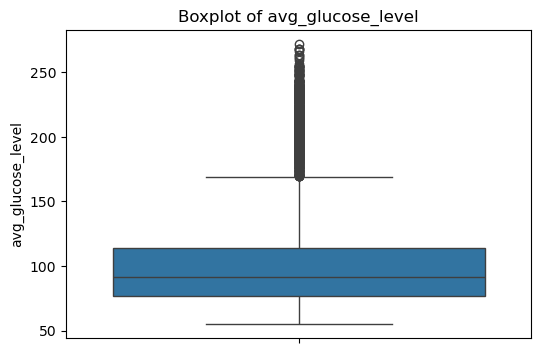

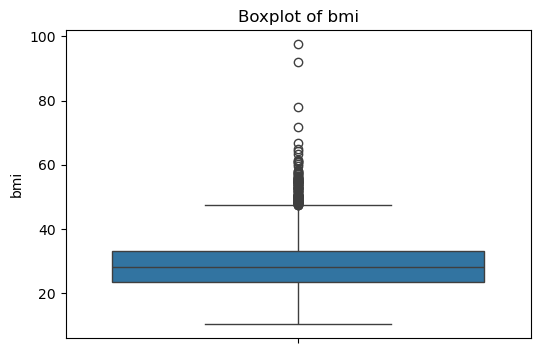

age: 0 potential outliers
avg_glucose_level: 627 potential outliers
bmi: 110 potential outliers


In [50]:
# -------------------------------
# 6. Initial insights and observations for outliers
# -------------------------------

# Imbalance in target variable 'stroke'
stroke_counts = data['stroke'].value_counts()
print("Stroke value counts:")
print(stroke_counts)
print(f"Percentage of stroke cases: {stroke_counts[1]/stroke_counts.sum()*100:.2f}%")

# Check for outliers in numeric columns using boxplots
numeric_features = ['age', 'avg_glucose_level', 'bmi']

for feature in numeric_features:
    plt.figure(figsize=(6,4))
    sns.boxplot(y=data[feature])
    plt.title(f"Boxplot of {feature}")
    plt.show()

for feature in numeric_features:
    Q1 = data[feature].quantile(0.25)
    Q3 = data[feature].quantile(0.75)
    IQR = Q3 - Q1
    outliers = data[(data[feature] < Q1 - 1.5*IQR) | (data[feature] > Q3 + 1.5*IQR)]
    print(f"{feature}: {len(outliers)} potential outliers")



# Notes to consider:
  - **stroke** is highly imbalanced (few positive cases)
- **bmi** has missing values
- Some numeric features like **avg_glucose_level** and **bmi** may contain outliers
- Correlation heatmap can hint which features are more related to stroke
- Categorical features distributions also important for modeling